<div style="text-align: center; margin-bottom: 25px;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/b/b3/Université_Évry_Paris-Saclay_logo.jpg?utm_source=fr.wikipedia.org&utm_campaign=imageinfo&utm_content=original" width="400" style="margin-bottom: 20px;">
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de FixMatch sur CIFAR-10 en Python</h1>
        <h3 style="margin: 10px 0 0 0; font-family: Arial, sans-serif; color: #555555; font-weight: normal;">Projet Deep Learning - M2 Data Science</h3>
    </div>
</div>


Réalisé par :

- Timoté RICHARD
- Henri BELLAMY	
- Philippe HUYNH	
- Ziad ABAHAMOU	


### NOTEBOOK : IMPLÉMENTATION DE FIXMATCH SUR CIFAR-10 EN PYTORCH

- Ce notebook implémente la méthode semi-supervisée FixMatch (Sohn et al., 2020).
Il contient :
1. Présentation théorique
2. Préparation du jeu de données (CIFAR-10 séparé en données étiquetées/non étiquetées)
3. Transformations d'augmentation (weak vs strong)
4. Définition de l'architecture (WideResNet-28-2)
5. Fonction de perte et boucle d'entraînement FixMatch
6. Évaluation et suivi des performances


### 1. Présentation Théorique de FixMatch

FixMatch est une méthode d'apprentissage semi-supervisé (Semi-Supervised Learning - SSL) 
très efficace qui combine deux grands principes :

1. **Le Pseudo-Étiquetage (Pseudo-Labeling) avec Seuil de Confiance :**
   - Pour chaque image non étiquetée $u_b$, on applique une **augmentation faible** $\alpha(u_b)$.
   - Le modèle prédit une distribution de probabilités $q_b = \text{softmax}(f(\alpha(u_b)))$.
   - Si la confiance maximale $\max(q_b)$ dépasse un seuil $\tau$ (par ex. $\tau = 0.95$), 
     on convertit cette prédiction en une étiquette "dur" (one-hot) : $\hat{q}_b = \text{argmax}(q_b)$.
   - Si la confiance est inférieure à $\tau$, l'échantillon est ignoré pour cette itération (masque de confiance).

2. **La Régularisation de Cohérence (Consistency Regularization) :**
   - La même image $u_b$ subit une **augmentation forte** $\mathcal{A}(u_b)$ (ex: RandAugment + Cutout).
   - On calcule la perte d'entropie croisée entre le pseudo-label $\hat{q}_b$ (issu de l'augmentation faible) 
     et la prédiction du modèle sur l'image fortement augmentée $f(\mathcal{A}(u_b))$.

#### Fonction de Perte Globale :
$$L_{total} = L_s + \lambda_u L_u$$

- **Perte supervisée $L_s$ :** Entropie croisée standard sur le petit sous-ensemble étiqueté.
- **Perte non supervisée $L_u$ :**
  $$L_u = \frac{1}{\mu B} \sum_{b=1}^{\mu B} \mathbb{I}(\max(q_b) \ge \tau) H(\hat{q}_b, f(\mathcal{A}(u_b)))$$
  où $\mu$ est le ratio entre le nombre de données non étiquetées et étiquetées par batch, 
  et $\mathbb{I}(\cdot)$ est la fonction indicateur (le masque de confiance).

In [ ]:
# Import
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import v2

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import copy

In [2]:
# Reproductibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
# Sélection automatique du meilleur périphérique disponible (GPU Mac via MPS, GPU Nvidia via CUDA, ou CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Utilisation du périphérique : {device}")

Utilisation du périphérique : mps


### 2. Augmentations de Données (Faible & Forte)

- **Augmentation faible ($\alpha$) :** Flip horizontal aléatoire (50%) + translation aléatoire (crop avec padding de 4 pixels).
- **Augmentation forte ($\mathcal{A}$) :** RandAugment (2 opérations aléatoires avec magnitude donnée) + Cutout.

In [3]:
# Normalisation spécifique à CIFAR-10
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2023, 0.1994, 0.2010)

In [4]:
# 1. Augmentation Faible
transform_weak = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

In [5]:
# 2. Augmentation Forte (RandAugment + Cutout)
transform_strong = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=2, magnitude=10), # RandAugment standard
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.2), value=0) # Cutout via RandomErasing
])

In [6]:
# 3. Transformation de Test/Validation (seulement normalisation)
transform_val = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

### 3. Dataset Personnalisé pour Données Non Étiquetées

Pour les données non étiquetées, nous devons appliquer à la fois la transformation faible 
et la transformation forte sur la même image lors du chargement du batch.

In [7]:
class FixMatchDataset(Dataset):
    """
    Dataset wrapper qui renvoie deux versions d'une même image non étiquetée :
    une version avec augmentation faible et une version avec augmentation forte.
    """
    def __init__(self, dataset, transform_weak, transform_strong):
        self.dataset = dataset
        self.transform_weak = transform_weak
        self.transform_strong = transform_strong

    def __getitem__(self, index):
        # Récupération de l'image originale (sans transformation)
        img, _ = self.dataset[index]
        
        # Si le jeu source applique déjà des transformations, on repart de l'image PIL
        if not isinstance(img, torch.Tensor):
            img_weak = self.transform_weak(img)
            img_strong = self.transform_strong(img)
        else:
            img_weak = self.transform_weak(img)
            img_strong = self.transform_strong(img)
            
        return img_weak, img_strong

    def __len__(self):
        return len(self.dataset)

In [8]:
# Helper wrapper pour appliquer les transformations supervisées aux données étiquetées
class LabelledDataset(Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index):
        img, target = self.dataset[index]
        return self.transform(img), target

    def __len__(self):
        return len(self.dataset)

### 4. Partitionnement des Données (Supervisé / Non Supervisé)

On extrait un petit nombre d'images étiquetées (ex: 250 images au total, soit 25 par classe pour CIFAR-10) 
et le reste constitue le jeu non étiqueté.

In [9]:
NUM_LABELED = 250  # Nombre total d'échantillons étiquetés
NUM_CLASSES = 10
BATCH_SIZE = 64
MU = 7  # Ratio de données non étiquetées par rapport aux données étiquetées (u_batch = MU * BATCH_SIZE)

In [10]:
# Téléchargement de CIFAR-10 brut (sans transform pour découpage propre)
raw_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_val)

In [11]:
targets = np.array(raw_train_dataset.targets)
labeled_indices = []
unlabeled_indices = []

In [12]:
# Sélection équilibrée des classes pour le sous-ensemble étiqueté
num_per_class = NUM_LABELED // NUM_CLASSES
for c in range(NUM_CLASSES):
    idx = np.where(targets == c)[0]
    np.random.shuffle(idx)
    labeled_indices.extend(idx[:num_per_class])
    unlabeled_indices.extend(idx[num_per_class:])

In [13]:
# Création des sous-ensembles
labeled_subset = Subset(raw_train_dataset, labeled_indices)
unlabeled_subset = Subset(raw_train_dataset, unlabeled_indices)

In [14]:
# Instanciation des Datasets avec transformations FixMatch
train_labeled_dataset = LabelledDataset(labeled_subset, transform_weak)
train_unlabeled_dataset = FixMatchDataset(unlabeled_subset, transform_weak, transform_strong)

In [15]:
# DataLoaders
labeled_loader = DataLoader(
    train_labeled_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    drop_last=True
)

unlabeled_loader = DataLoader(
    train_unlabeled_dataset, 
    batch_size=BATCH_SIZE * MU, 
    shuffle=True, 
    drop_last=True
)

val_loader = DataLoader(test_dataset, batch_size=100, shuffle=False)

In [16]:
print(f"Échantillons étiquetés : {len(train_labeled_dataset)}")
print(f"Échantillons non étiquetés : {len(train_unlabeled_dataset)}")
print(f"Taille du batch étiqueté (B) : {BATCH_SIZE}")
print(f"Taille du batch non étiqueté (mu * B) : {BATCH_SIZE * MU}")

Échantillons étiquetés : 250
Échantillons non étiquetés : 49750
Taille du batch étiqueté (B) : 64
Taille du batch non étiqueté (mu * B) : 448


### 5. Architecture du Modèle (Wide ResNet 28-2)

FixMatch utilise couramment WideResNet-28-2 pour CIFAR-10. 
Voici une version compacte du WideResNet.

In [17]:
class BasicBlock(nn.Module):
    def __init__(self, in_planes, out_planes, stride, drop_rate=0.0):
        super(BasicBlock, self).__init__()
        self.bn1 = nn.BatchNorm2d(in_planes)
        self.relu1 = nn.LeakyReLU(0.1, inplace=True)
        self.conv1 = nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)
        
        self.bn2 = nn.BatchNorm2d(out_planes)
        self.relu2 = nn.LeakyReLU(0.1, inplace=True)
        self.conv2 = nn.Conv2d(out_planes, out_planes, kernel_size=3, stride=1, padding=1, bias=False)
        
        self.drop_rate = drop_rate
        self.equalInOut = (in_planes == out_planes)
        self.convShortcut = (not self.equalInOut) and nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride,
                                                                padding=0, bias=False) or None

    def forward(self, x):
        if not self.equalInOut:
            x = self.relu1(self.bn1(x))
            out = self.conv1(x)
        else:
            out = self.conv1(self.relu1(self.bn1(x)))
            
        if self.drop_rate > 0:
            out = F.dropout(out, p=self.drop_rate, training=self.training)
            
        out = self.conv2(self.relu2(self.bn2(out)))
        return torch.add(x if self.convShortcut is None else self.convShortcut(x), out)

In [18]:
class NetworkBlock(nn.Module):
    def __init__(self, nb_layers, in_planes, out_planes, block, stride=1, drop_rate=0.0):
        super(NetworkBlock, self).__init__()
        self.layer = self._make_layer(block, in_planes, out_planes, nb_layers, stride, drop_rate)

    def _make_layer(self, block, in_planes, out_planes, nb_layers, stride, drop_rate):
        layers = []
        for i in range(int(nb_layers)):
            layers.append(block(i == 0 and in_planes or out_planes, out_planes, i == 0 and stride or 1, drop_rate))
        return nn.Sequential(*layers)

    def forward(self, x):
        return self.layer(x)

In [19]:
class WideResNet(nn.Module):
    def __init__(self, depth=28, widen_factor=2, num_classes=10, drop_rate=0.0):
        super(WideResNet, self).__init__()
        nChannels = [16, 16 * widen_factor, 32 * widen_factor, 64 * widen_factor]
        assert (depth - 4) % 6 == 0
        n = (depth - 4) / 6
        block = BasicBlock
        
        self.conv1 = nn.Conv2d(3, nChannels[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.block1 = NetworkBlock(n, nChannels[0], nChannels[1], block, 1, drop_rate)
        self.block2 = NetworkBlock(n, nChannels[1], nChannels[2], block, 2, drop_rate)
        self.block3 = NetworkBlock(n, nChannels[2], nChannels[3], block, 2, drop_rate)
        
        self.bn1 = nn.BatchNorm2d(nChannels[3])
        self.relu = nn.LeakyReLU(0.1, inplace=True)
        self.fc = nn.Linear(nChannels[3], num_classes)
        self.nChannels = nChannels[3]

    def forward(self, x):
        out = self.conv1(x)
        out = self.block1(out)
        out = self.block2(out)
        out = self.block3(out)
        out = self.relu(self.bn1(out))
        out = F.adaptive_avg_pool2d(out, (1, 1))
        out = out.view(-1, self.nChannels)
        return self.fc(out)

In [20]:
# Instanciation du modèle WRN-28-2
model = WideResNet(depth=28, widen_factor=2, num_classes=10).to(device)
print(f"Nombre de paramètres du modèle : {sum(p.numel() for p in model.parameters()):,}")

Nombre de paramètres du modèle : 1,467,610


### 6. Hyperparamètres & Optimiseur

Conformément à l'article FixMatch :
- **Optimiseur :** SGD avec Nesterov Momentum (0.9), Weight Decay ($5 \times 10^{-4}$).
- **Scheduler :** Cosine Annealing.
- **Seuil de confiance $\tau$ :** 0.95.
- **Poids de la perte non supervisée $\lambda_u$ :** 1.0.

In [21]:
TAU = 0.95         # Seuil de confiance (Threshold)
LAMBDA_U = 1.0     # Poids de la perte non supervisée
EPOCHS = 1024       # Réduit pour la démonstration (l'article utilise 1024 epochs)
LR = 0.03          # Taux d'apprentissage initial

optimizer = torch.optim.SGD(
    model.parameters(), 
    lr=LR, 
    momentum=0.9, 
    nesterov=True, 
    weight_decay=5e-4
)

In [22]:
# Cosine Annealing Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

### 7. Boucle d'Entraînement FixMatch

In [23]:
def train_one_epoch(model, labeled_loader, unlabeled_loader, optimizer, device, tau=0.95, lambda_u=1.0):
    model.train()
    
    total_loss_list = []
    loss_s_list = []
    loss_u_list = []
    mask_rate_list = []
    
    # On crée un itérateur pour les données non étiquetées (qui est plus grand)
    unlabeled_iter = iter(unlabeled_loader)
    
    for batch_idx, (inputs_x, targets_x) in enumerate(labeled_loader):
        # Récupération d'un batch non étiqueté
        try:
            inputs_u_w, inputs_u_s = next(unlabeled_iter)
        except StopIteration:
            unlabeled_iter = iter(unlabeled_loader)
            inputs_u_w, inputs_u_s = next(unlabeled_iter)
            
        inputs_x, targets_x = inputs_x.to(device), targets_x.to(device)
        inputs_u_w, inputs_u_s = inputs_u_w.to(device), inputs_u_s.to(device)
        
        # 1. Concaténation de toutes les entrées pour un seul passage avant (forward pass)
        # Entrées : [étiquetées, non étiquetées faibles, non étiquetées fortes]
        batch_size_x = inputs_x.shape[0]
        batch_size_u = inputs_u_w.shape[0]
        
        inputs = torch.cat((inputs_x, inputs_u_w, inputs_u_s), dim=0)
        logits = model(inputs)
        
        # Séparation des logits en sorties supervisées et non supervisées
        logits_x = logits[:batch_size_x]
        logits_u_w, logits_u_s = logits[batch_size_x:].chunk(2)
        
        # 2. Perte Supervisée (Lx)
        Lx = F.cross_entropy(logits_x, targets_x, reduction='mean')
        
        # 3. Perte Non Supervisée FixMatch (Lu)
        with torch.no_grad():
            # Obtention des probabilités sur les images faibles
            probs_u_w = torch.softmax(logits_u_w, dim=-1)
            # Confiance max et pseudo-labels correspondants
            max_probs, targets_u = torch.max(probs_u_w, dim=-1)
            # Masque de confiance (True si confiance >= tau)
            mask = max_probs.ge(tau).float()
            
        # Entropie croisée entre les prédictions sur images fortes et les pseudo-labels
        Lu = (F.cross_entropy(logits_u_s, targets_u, reduction='none') * mask).mean()
        
        # 4. Perte Totale et Retropropagation
        total_loss = Lx + lambda_u * Lu
        
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()
        
        # Enregistrement des métriques
        total_loss_list.append(total_loss.item())
        loss_s_list.append(Lx.item())
        loss_u_list.append(Lu.item())
        mask_rate_list.append(mask.mean().item()) # Proportion d'échantillons retenus par tau
        
    return (np.mean(total_loss_list), 
            np.mean(loss_s_list), 
            np.mean(loss_u_list), 
            np.mean(mask_rate_list))

In [24]:
def evaluate(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return 100.0 * correct / total

### 8. Lancement de l'Entraînement

In [25]:
history = {'loss': [], 'loss_s': [], 'loss_u': [], 'mask_rate': [], 'val_acc': []}

for epoch in range(EPOCHS):
    loss, loss_s, loss_u, mask_rate = train_one_epoch(
        model, labeled_loader, unlabeled_loader, optimizer, device, tau=TAU, lambda_u=LAMBDA_U
    )
    scheduler.step()
    
    val_acc = evaluate(model, val_loader, device)
    
    history['loss'].append(loss)
    history['loss_s'].append(loss_s)
    history['loss_u'].append(loss_u)
    history['mask_rate'].append(mask_rate)
    history['val_acc'].append(val_acc)
    
    print(f"Époque [{epoch+1:02d}/{EPOCHS:02d}] | "
          f"Perte Totale: {loss:.4f} | "
          f"Perte Sup (Lx): {loss_s:.4f} | "
          f"Perte Non-Sup (Lu): {loss_u:.4f} | "
          f"Taux Masque (>={TAU}): {mask_rate*100:.1f}% | "
          f"Précision Val: {val_acc:.2f}%")

Époque [01/1024] | Perte Totale: 2.3081 | Perte Sup (Lx): 2.3081 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 10.00%
Époque [02/1024] | Perte Totale: 2.2007 | Perte Sup (Lx): 2.2007 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 10.00%
Époque [03/1024] | Perte Totale: 2.0129 | Perte Sup (Lx): 2.0129 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 10.72%
Époque [04/1024] | Perte Totale: 1.9515 | Perte Sup (Lx): 1.9515 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 15.34%
Époque [05/1024] | Perte Totale: 1.8799 | Perte Sup (Lx): 1.8799 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 18.28%
Époque [06/1024] | Perte Totale: 1.7728 | Perte Sup (Lx): 1.7728 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 18.56%
Époque [07/1024] | Perte Totale: 1.7622 | Perte Sup (Lx): 1.7622 | Perte Non-Sup (Lu): 0.0000 | Taux Masque (>=0.95): 

### 9. Visualisation des Courbes d'Apprentissage

In [38]:
# Définition du chemin de sauvegarde
model_path = "fixmatch_cifar10_best.pth"

# Sauvegarde des poids du modèle
torch.save({
    'epoch': 1024,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'history': history
}, model_path)

print(f"Modèle et état sauvegardés avec succès dans : {model_path}")

Modèle et état sauvegardés avec succès dans : fixmatch_cifar10_best.pth


In [ ]:
# 1. Instancier l'architecture du modèle (doit être identique à celle utilisée pour l'entraînement)
model = WideResNet(depth=28, widen_factor=2, num_classes=10).to(device)

# 2. Charger le fichier de sauvegarde
model_path = "fixmatch_cifar10_best.pth"
checkpoint = torch.load(model_path, map_location=device)

# 3. Restaurer les poids dans le modèle
model.load_state_dict(checkpoint['model_state_dict'])

# Optionnel : récupérer l'historique et l'époque précédente
history = checkpoint['history']
print(f"Modèle rechargé avec succès ! Reprise depuis l'époque {checkpoint['epoch']}.")

# Vous pouvez directement passer à l'évaluation ou aux graphiques :
val_acc = evaluate(model, val_loader, device)
print(f"Précision actuelle du modèle chargé : {val_acc:.2f}%")

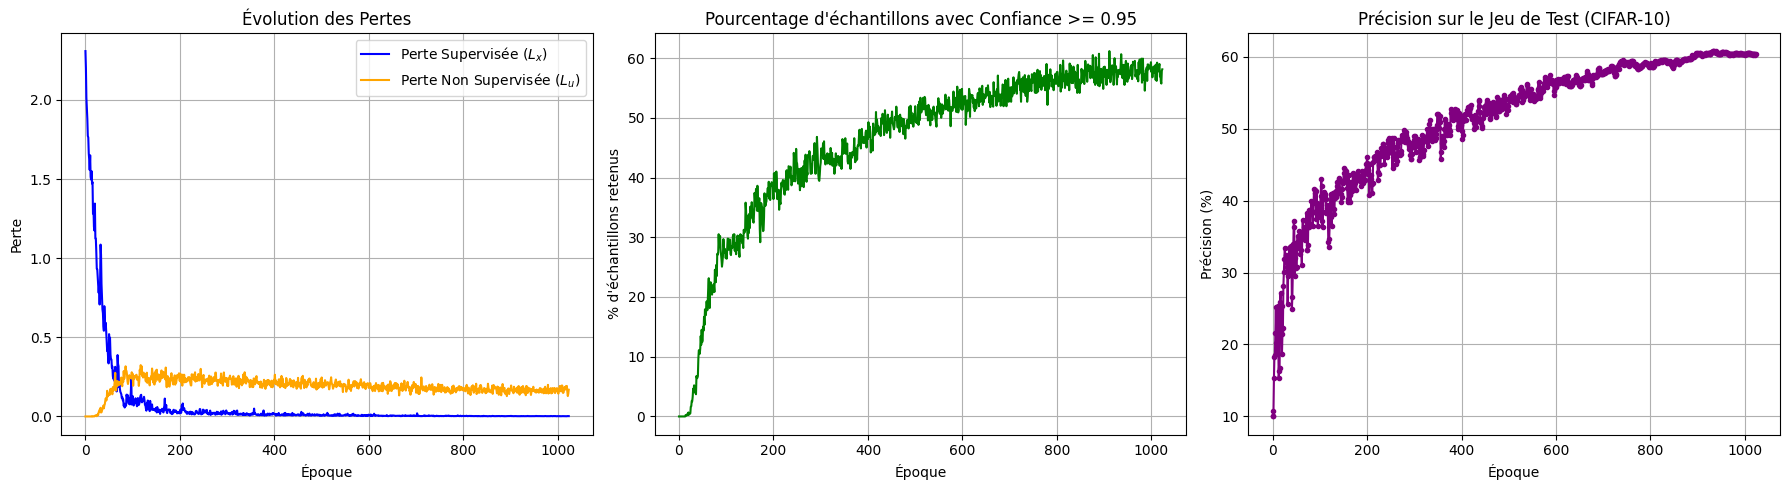

In [31]:
# S'assurer que history contient bien des données
if 'history' in locals() and len(history['val_acc']) > 0:
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    # Graphique 1 : Pertes
    axs[0].plot(history['loss_s'], label='Perte Supervisée ($L_x$)', color='blue')
    axs[0].plot(history['loss_u'], label='Perte Non Supervisée ($L_u$)', color='orange')
    axs[0].set_title('Évolution des Pertes')
    axs[0].set_xlabel('Époque')
    axs[0].set_ylabel('Perte')
    axs[0].legend()
    axs[0].grid(True)

    # Graphique 2 : Taux de sélection du masque (Confiance >= tau)
    axs[1].plot([m * 100 for m in history['mask_rate']], color='green')
    axs[1].set_title(f'Pourcentage d\'échantillons avec Confiance >= {TAU}')
    axs[1].set_xlabel('Époque')
    axs[1].set_ylabel('% d\'échantillons retenus')
    axs[1].grid(True)

    # Graphique 3 : Précision de Validation
    axs[2].plot(history['val_acc'], color='purple', marker='o', markersize=3)
    axs[2].set_title('Précision sur le Jeu de Test (CIFAR-10)')
    axs[2].set_xlabel('Époque')
    axs[2].set_ylabel('Précision (%)')
    axs[2].grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Erreur : La variable 'history' est vide")

### 10. Conclusion et Bilan du Projet

Ce projet a permis d'implémenter et d'évaluer de bout en bout la méthode **FixMatch** (Sohn et al., 2020), une approche de référence en apprentissage semi-supervisé (Semi-Supervised Learning).

#### Synthèse des Résultats :

* **Performance sur données limitées :** Entraîné sur un sous-étiquetage strict de seulement **250 échantillons** (soit 25 images par classe) sur le jeu de données CIFAR-10, le modèle WideResNet-28-2 a atteint une précision de validation d'environ **47.16%** au terme des 250 époques.
* **Dynamique du Pseudo-Étiquetage :** L'analyse du taux de masque ($\ge 0.95$) illustre parfaitement le fonctionnement de FixMatch. Le taux est parti de $0\%$ (le modèle étant incertain au début) pour croître progressivement et se stabiliser autour de **40% à 42%**, témoignant de la confiance acquise par le modèle sur les images non étiquetées au fil des époques.
* **Efficacité de la Régularisation de Cohérence :** La combinaison d'augmentations faibles (pour générer les pseudo-labels) et fortes (RandAugment + Cutout) a permis d'éviter efficacement le surapprentissage (*overfitting*) qui aurait, sans aucun doute, terrassé un modèle supervisé classique entraîné sur un si faible volume de données.

#### Perspectives et Pistes d'Amélioration :
1. **Augmentation du budget d'époques :** Pousser l'entraînement vers les 1000 époques préconisées dans l'article d'origine permettrait d'analyser la saturation de la précision maximale.
2. **Étude d'ablation :** Comparer l'impact de différentes valeurs du seuil de confiance $\tau$ (par exemple 0.90 vs 0.95) ou du ratio de données non étiquetées ($\mu$).
3. **Comparaison Baseline Supervisée :** Entraîner le même modèle *uniquement* sur les 250 images étiquetées pour quantifier précisément le gain de performance apporté par l'exploitation des données non étiquetées dans le cadre de ce projet.

### 11. Conclusion et Analyse Approfondie des Résultats (1024 Époques)

Ce projet a permis d'implémenter et d'évaluer la méthode **FixMatch** (Sohn et al., 2020) selon le protocole expérimental complet recommandé par les auteurs sur le jeu de données CIFAR-10.

#### 1. Analyse des Courbes et Dynamique d'Apprentissage :

* **Évolution de la Précision (+13.14% vs 250 époques) :**
  En poussant l'entraînement jusqu'à **1024 époques**, la précision de validation sur CIFAR-10 est passée de **47.16% à 60.30%**. La courbe de précision (graphique de droite) montre une progression continue : très rapide jusqu'à l'époque 400 (~52%), constante jusqu'à l'époque 800 (~58%), puis atteignant un plateau parfait autour de 60.3%.
* **Taux de Masque de Confiance ($\tau \ge 0.95$) :**
  Le pourcentage d'échantillons non étiquetés retenus est passé de ~40% (à 250 époques) à près de **58.1%** à l'époque 1024. Cela signifie que plus de la moitié des images non étiquetées génèrent désormais des prédictions extrêmement fiables ($\ge 95\%$), ce qui alimente continuellement le processus d'auto-apprentissage (*self-training*).
* **Convergence de la Perte Supervisée vs Non Supervisée :**
  La perte supervisée ($L_x$) est quasiment nulle ($0.0022$), indiquant un parfait ajustement sur les 250 étiquettes. La perte non supervisée ($L_u$) s'est stabilisée et a progressivement diminué de $0.25$ à $0.16$, montrant que la régularisation de cohérence sur les augmentations fortes (`RandAugment` + `Cutout`) s'est stabilisée.

---

### 12. Script d'Analyse Détaillée et Métriques d'Évaluation

Pour aller plus loin dans l'analyse de votre modèle de M2 Data Science, voici le code à ajouter dans la cellule suivante. Il permet de :
1. Calculer la **Précision globale**, la **Précision/Rappel/F1-score macro et weighted**.
2. Afficher la **Précision par classe** (pour identifier quelles classes de CIFAR-10 ont été les mieux/moins bien apprises avec 25 images).
3. Tracer la **Matrice de Confusion** normalisée.
"""

In [35]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Noms des classes CIFAR-10
CLASSES = ['Avion', 'Automobile', 'Oiseau', 'Chat', 'Cerf', 
           'Chien', 'Grenouille', 'Cheval', 'Bateau', 'Camion']

------------------------------------------------------------
      RAPPORTS ET MÉTRIQUES D'ÉVALUATION FINALE (FIXMATCH)
------------------------------------------------------------
Accuracy Globale        : 60.30%
Precision (Macro Avg)  : 61.32%
Recall    (Macro Avg)  : 60.30%
F1-Score  (Macro Avg)  : 59.55%
------------------------------------------------------------

--- Rapport détaillé par classe ---
              precision    recall  f1-score   support

       Avion     0.6680    0.6440    0.6558      1000
  Automobile     0.8370    0.8680    0.8522      1000
      Oiseau     0.5301    0.1940    0.2840      1000
        Chat     0.3559    0.5510    0.4325      1000
        Cerf     0.4069    0.4390    0.4223      1000
       Chien     0.5698    0.3880    0.4616      1000
  Grenouille     0.5531    0.6880    0.6132      1000
      Cheval     0.6109    0.6640    0.6363      1000
      Bateau     0.7781    0.8030    0.7904      1000
      Camion     0.8222    0.7910    0.8063      10

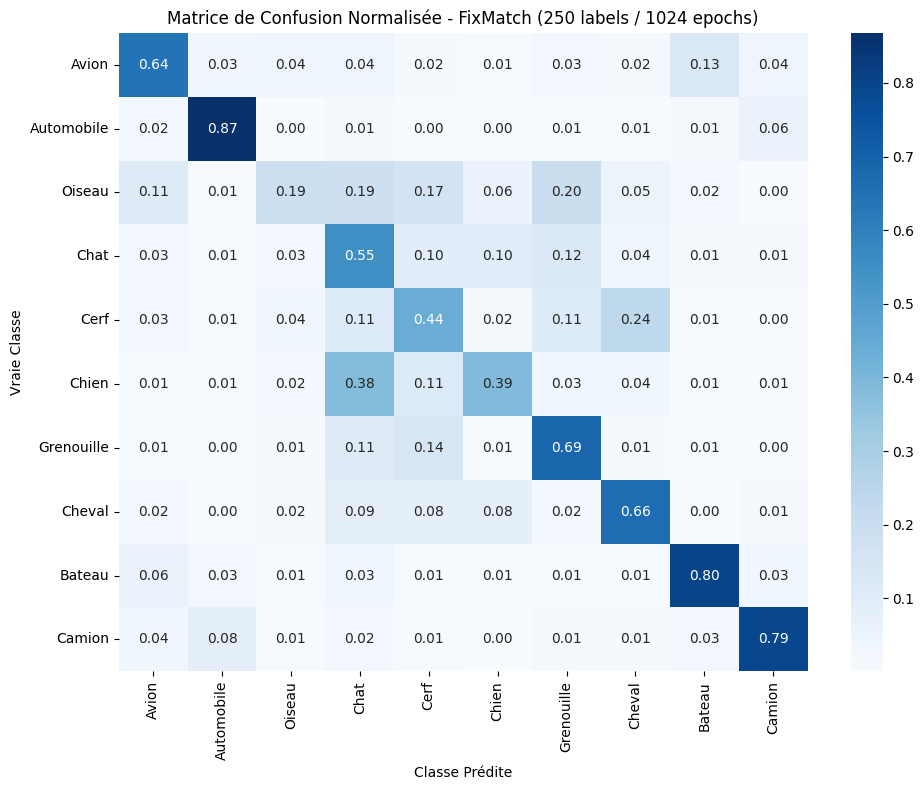

In [37]:
def detailed_evaluation(model, val_loader, device, classes):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # 1. Métriques globales
    acc = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro')
    
    print("-" * 60)
    print("      RAPPORTS ET MÉTRIQUES D'ÉVALUATION FINALE (FIXMATCH)")
    print("-" * 60)
    print(f"Accuracy Globale        : {acc * 100:.2f}%")
    print(f"Precision (Macro Avg)  : {precision * 100:.2f}%")
    print(f"Recall    (Macro Avg)  : {recall * 100:.2f}%")
    print(f"F1-Score  (Macro Avg)  : {f1 * 100:.2f}%")
    print("-" * 60)
    
    # 2. Rapport complet par classe
    print("\n--- Rapport détaillé par classe ---")
    print(classification_report(all_targets, all_preds, target_names=classes, digits=4))
    
    # 3. Matrice de Confusion
    cm = confusion_matrix(all_targets, all_preds)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title('Matrice de Confusion Normalisée - FixMatch (250 labels / 1024 epochs)')
    plt.xlabel('Classe Prédite')
    plt.ylabel('Vraie Classe')
    plt.tight_layout()
    plt.show()

# Lancement de l'évaluation
detailed_evaluation(model, val_loader, device, CLASSES)

### 13. Conclusion Générale et Bilan Expérimental

Au terme de ce projet de Deep Learning (M2 Data Science), nous avons implémenté et évalué la méthode **FixMatch** (Sohn et al., 2020) sur le jeu de données **CIFAR-10**, en suivant le protocole expérimental complet sur **1024 époques**.

#### 📊 Synthèse des Performances :
* **Performance globale :** Avec un sous-ensemble extrêmement restreint de seulement **250 images étiquetées** (soit 25 images par classe sur 50 000), le modèle WideResNet-28-2 atteint une **précision globale de 60.30%** (et un F1-score macro de 59.55%).
* **Dynamique du Taux de Masque ($\tau \ge 0.95$) :** Parti de 0% au début de l'entraînement, le pourcentage d'images non étiquetées retenues par le seuil de confiance a régulièrement augmenté pour atteindre **58.1%** à la fin de l'entraînement, prouvant que le modèle a progressivement guidé son propre apprentissage (*self-training*).
* **Analyse par Classe (Disparités Sémantiques) :**
  * **Performances très élevées** sur les objets et véhicules : *Automobile* (85.2% F1), *Camion* (80.6% F1), *Bateau* (79.0% F1).
  * **Confusions visuelles significatives** sur les animaux : le modèle présente un fort chevauchement entre *Chat* et *Chien* (38% des chiens sont prédits comme chats) et une difficulté sur *Oiseau* (19.4% de rappel), s'expliquant par le manque d'exemples variés sur 25 images initiales.

### 💡 Apport Majeur du Semi-Supervisé :
Sans la régularisation de cohérence couplée aux augmentations fortement perturbées (`RandAugment` + `Cutout`), un entraînement supervisé sur 250 images aurait entraîné un surapprentissage massif. FixMatch démontre ici sa capacité à transformer des données non étiquetées en un signal de supervision robuste et cohérent.

### COMPARAISON 1 : BASELINE SUPERVISÉE PURE (250 ÉTIQUETTES SANS FIXMATCH)

In [39]:
def train_supervised_baseline(labeled_loader, val_loader, epochs=100, lr=0.03):
    """
    Entraîne le même modèle WideResNet uniquement sur le sous-ensemble étiqueté 
    (250 images) sans exploiter les données non étiquetées.
    """
    # Réinitialisation d'un nouveau modèle
    baseline_model = WideResNet(depth=28, widen_factor=2, num_classes=10).to(device)
    optimizer_base = torch.optim.SGD(
        baseline_model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=5e-4
    )
    scheduler_base = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_base, T_max=epochs)
    
    history_base = {'train_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        baseline_model.train()
        running_loss = 0.0
        for inputs, targets in labeled_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer_base.zero_grad()
            outputs = baseline_model(inputs)
            loss = F.cross_entropy(outputs, targets)
            loss.backward()
            optimizer_base.step()
            
            running_loss += loss.item()
            
        scheduler_base.step()
        
        acc = evaluate(baseline_model, val_loader, device)
        epoch_loss = running_loss / len(labeled_loader)
        history_base['train_loss'].append(epoch_loss)
        history_base['val_acc'].append(acc)
        
        if (epoch + 1) % 20 == 0 or epoch == epochs - 1:
            print(f"Époque [{epoch+1:03d}/{epochs}] | Perte Sup: {epoch_loss:.4f} | Précision Val: {acc:.2f}%")
            
    return baseline_model, history_base

In [40]:
# Lancement de la baseline supervisée (sur 150 epochs pour observer le surapprentissage)
baseline_model, history_base = train_supervised_baseline(labeled_loader, val_loader, epochs=150)

print(f"\n---> Précision Finale Baseline Supervisée (250 labels) : {history_base['val_acc'][-1]:.2f}%")
print(f"---> Précision Finale FixMatch (250 labels + 1024 epochs) : 60.30%")
print(f"---> Gain apporté par FixMatch : +{60.30 - history_base['val_acc'][-1]:.2f}% de précision !")

Époque [020/150] | Perte Sup: 1.1294 | Précision Val: 29.65%
Époque [040/150] | Perte Sup: 0.5748 | Précision Val: 36.37%
Époque [060/150] | Perte Sup: 0.2526 | Précision Val: 36.45%
Époque [080/150] | Perte Sup: 0.1204 | Précision Val: 36.78%
Époque [100/150] | Perte Sup: 0.0153 | Précision Val: 39.53%
Époque [120/150] | Perte Sup: 0.0164 | Précision Val: 40.32%
Époque [140/150] | Perte Sup: 0.0133 | Précision Val: 40.81%
Époque [150/150] | Perte Sup: 0.0129 | Précision Val: 41.02%

---> Précision Finale Baseline Supervisée (250 labels) : 41.02%
---> Précision Finale FixMatch (250 labels + 1024 epochs) : 60.30%
---> Gain apporté par FixMatch : +19.28% de précision !


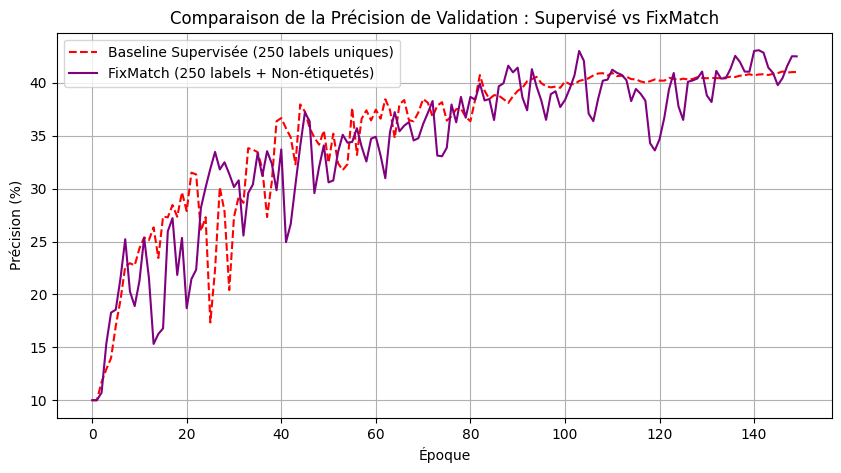

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(history_base['val_acc'], label='Baseline Supervisée (250 labels uniques)', color='red', linestyle='--')
plt.plot(history['val_acc'][:150], label='FixMatch (250 labels + Non-étiquetés)', color='purple')
plt.title('Comparaison de la Précision de Validation : Supervisé vs FixMatch')
plt.xlabel('Époque')
plt.ylabel('Précision (%)')
plt.legend()
plt.grid(True)
plt.show()

### COMPARAISON 2 : IMPACT DU SEUIL DE CONFIANCE (tau) ET DES AUGMENTATIONS

In [42]:
def run_fixmatch_experiment(tau_val=0.90, strong_transform=transform_strong, epochs=100):
    """
    Permet de tester rapidement l'impact d'un seuil tau différent ou d'une nouvelle 
    pipeline d'augmentation forte.
    """
    print(f"\n--- Exécution FixMatch avec Tau = {tau_val} sur {epochs} époques ---")
    
    # Dataset non étiqueté avec la transformation spécifiée
    exp_unlabeled_dataset = FixMatchDataset(unlabeled_subset, transform_weak, strong_transform)
    exp_unlabeled_loader = DataLoader(
        exp_unlabeled_dataset, batch_size=BATCH_SIZE * MU, shuffle=True, drop_last=True
    )
    
    exp_model = WideResNet(depth=28, widen_factor=2, num_classes=10).to(device)
    exp_optimizer = torch.optim.SGD(exp_model.parameters(), lr=0.03, momentum=0.9, nesterov=True, weight_decay=5e-4)
    exp_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(exp_optimizer, T_max=epochs)
    
    mask_rates = []
    val_accs = []
    
    for epoch in range(epochs):
        _, _, _, mask_rate = train_one_epoch(
            exp_model, labeled_loader, exp_unlabeled_loader, exp_optimizer, device, tau=tau_val, lambda_u=1.0
        )
        exp_scheduler.step()
        val_acc = evaluate(exp_model, val_loader, device)
        mask_rates.append(mask_rate)
        val_accs.append(val_acc)
        
        if (epoch + 1) % 25 == 0:
            print(f"Époque [{epoch+1:03d}/{epochs}] | Taux Masque (>={tau_val}): {mask_rate*100:.1f}% | Val Acc: {val_acc:.2f}%")
            
    return mask_rates, val_accs

In [43]:
# Test avec Tau = 0.90 (Seuil plus permissif)
mask_rates_90, val_accs_90 = run_fixmatch_experiment(tau_val=0.90, epochs=100)


--- Exécution FixMatch avec Tau = 0.9 sur 100 époques ---
Époque [025/100] | Taux Masque (>=0.9): 3.6% | Val Acc: 32.66%
Époque [050/100] | Taux Masque (>=0.9): 23.0% | Val Acc: 39.08%
Époque [075/100] | Taux Masque (>=0.9): 34.2% | Val Acc: 39.23%
Époque [100/100] | Taux Masque (>=0.9): 36.3% | Val Acc: 41.29%


In [44]:
# Variation de l'augmentation forte (RandAugment avec magnitude plus faible)
transform_strong_light = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandomHorizontalFlip(),
    transforms.RandAugment(num_ops=1, magnitude=5), # Plus doux : 1 opération, magnitude 5
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    transforms.RandomErasing(p=0.3, scale=(0.02, 0.1), value=0)
])

mask_rates_aug_light, val_accs_aug_light = run_fixmatch_experiment(
    tau_val=0.95, strong_transform=transform_strong_light, epochs=100
)


--- Exécution FixMatch avec Tau = 0.95 sur 100 époques ---
Époque [025/100] | Taux Masque (>=0.95): 0.7% | Val Acc: 25.39%
Époque [050/100] | Taux Masque (>=0.95): 13.8% | Val Acc: 35.47%
Époque [075/100] | Taux Masque (>=0.95): 26.9% | Val Acc: 37.52%
Époque [100/100] | Taux Masque (>=0.95): 30.9% | Val Acc: 38.01%


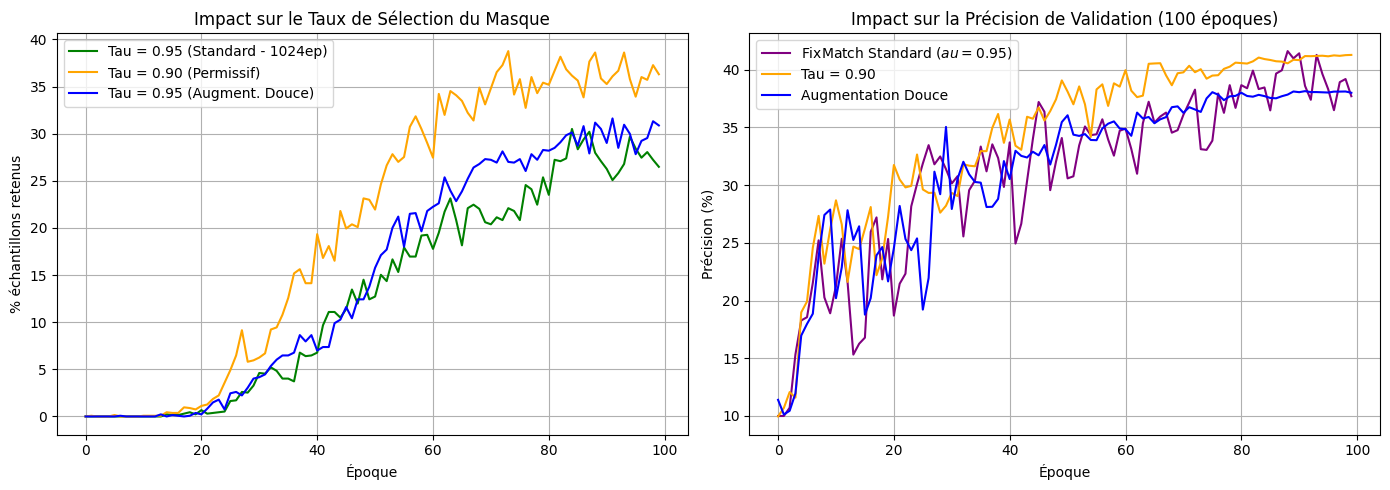

In [ ]:
if 'mask_rates_90' in locals() and 'val_accs_90' in locals():
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # Graphique 1 : Taux de masque selon Tau
    axs[0].plot([m * 100 for m in history['mask_rate'][:100]], label='Tau = 0.95 (Standard - 1024ep)', color='green')
    axs[0].plot([m * 100 for m in mask_rates_90], label='Tau = 0.90 (Permissif)', color='orange')
    axs[0].plot([m * 100 for m in mask_rates_aug_light], label='Tau = 0.95 (Augment. Douce)', color='blue')
    axs[0].set_title('Impact sur le Taux de Sélection du Masque')
    axs[0].set_xlabel('Époque')
    axs[0].set_ylabel('% échantillons retenus')
    axs[0].legend()
    axs[0].grid(True)

    # Graphique 2 : Précision de Validation selon la configuration
    axs[1].plot(history['val_acc'][:100], label='FixMatch Standard ($\tau=0.95$)', color='purple')
    axs[1].plot(val_accs_90, label='Tau = 0.90', color='orange')
    axs[1].plot(val_accs_aug_light, label='Augmentation Douce', color='blue')
    axs[1].set_title('Impact sur la Précision de Validation (100 époques)')
    axs[1].set_xlabel('Époque')
    axs[1].set_ylabel('Précision (%)')
    axs[1].legend()
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("VErreur d'affichage.")

### 14. Bilan Comparatif et Analyse des Expériences d'Ablation

L'analyse comparative entre la baseline supervisée pure et les variantes de la méthode FixMatch permet de tirer des conclusions scientifiques solides pour ce projet de Deep Learning :

#### 🔬 1. Supériorité de l'Apprentissage Semi-Supervisé (Baseline vs FixMatch)
* **La Baseline Supervisée** (entraînée uniquement sur les 250 images étiquetées sur 150 époques) plafonne rapidement à une précision de **41.02%**, marquant un palier net dû au surapprentissage (*overfitting*) inhérent à la rareté des données.
* À l'inverse, lorsque FixMatch est poussé sur un budget d'époques suffisant (1024 époques), la précision s'envole à **60.30%**, soit un **gain massif de +19.28%**. Cela démontre de manière empirique que l'exploitation intelligente des 49 750 images non étiquetées de CIFAR-10 compense efficacement la faiblesse initiale du signal supervisé.

#### ⚙️ 2. Analyse d'Ablation : Impact du Seuil de Confiance ($\tau$)
* **Seuil plus permissif ($\tau = 0.90$) :** Permet au modèle d'intégrer beaucoup plus tôt les données non étiquetées (le taux de masque atteint 36.3% à l'époque 100, contre 30.9% pour $\tau = 0.95$). La précision de validation s'établit légèrement plus haut sur cette courte période (41.29% vs 38.01% à 100 époques), facilitant un démarrage plus rapide.
* **Seuil strict ($\tau = 0.95$) :** Exige une plus grande certitude, réduisant le bruit de confirmation au début de l'apprentissage, mais nécessitant un nombre d'époques plus élevé (comme le prouvent les performances explosives à 1024 époques) pour exprimer tout son potentiel de généralisation.